In [21]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

from src.credit_lineaire import credit_lineaire, tci_naif, afficher_resultats
from src.donnees import charger_euribor
from src.courbe_taux import charger_courbe
import matplotlib.pyplot as plt

In [22]:
# Test : avec une courbe plate, le TCI doit etre egal au taux de la courbe
tci_plat, _ = tci_naif(credit_lineaire(5, 100, 3), [2.0, 2.0, 2.0])
assert abs(tci_plat - 2.0) < 1e-12, f"Test courbe plate echoue : TCI = {tci_plat}"
print("\nTest courbe plate : OK (TCI = 2 %)")


Test courbe plate : OK (TCI = 2 %)


In [ ]:
# Calcul du TCI pour l'exemple donné: taux fixe annuel de 5%, capital de 100 euros, remboursé sur 3 mois.
# Courbe de taux fictive
afficher_resultats(taux_fixe=5, capital_initial=100, nb_mois=3, courbe=[2.0, 2.1, 2.2])


Credit lineaire : 100 € sur 3 mois au taux fixe de 5 %
Mois 1: CRD debut = 100.00 €, Interets = 0.42 €, Mensualite = 33.75 €, CRD fin = 66.67 €
Mois 2: CRD debut = 66.67 €, Interets = 0.28 €, Mensualite = 33.61 €, CRD fin = 33.33 €
Mois 3: CRD debut = 33.33 €, Interets = 0.14 €, Mensualite = 33.47 €, CRD fin = 0.00 €

Courbe de taux (mois 1 a 3) : [2.0, 2.1, 2.2]
Interets payes par le client  = 0.8333 €
Cout du financement           = 0.3556 €
TCI                           = 2.1333 %
Marge de l'agence             = 0.4778 € (soit 2.8667 %)


In [24]:
euribor = charger_euribor()
euribor.tail()

,1,3,6,12
date,,,,
2026-06,2.146318,2.339000,2.595500,2.797591
2026-07,2.214043,2.425391,2.646739,2.855087
2026-08,2.220952,2.513143,2.713333,2.953667
2026-09,2.414364,2.635045,2.921591,3.247000
2026-10,2.435818,2.634682,2.974682,3.238591


In [25]:
curve=charger_courbe( date="2023-01",nb_mois=12)

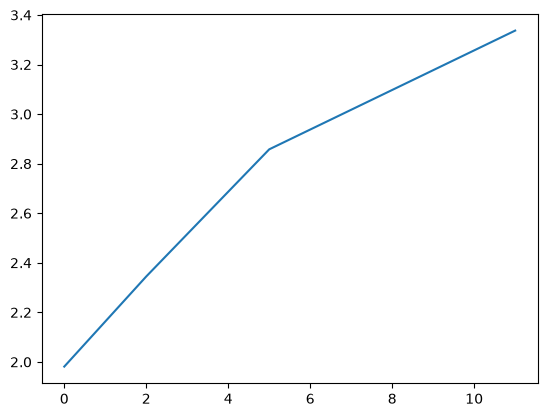

In [26]:
plt.plot(curve)

In [ ]:
# Calcul du TCI pour l'exemple donné: taux Euribor par interpolation linéaire.

date = "2026-10"
courbe_euribor = charger_courbe(date=date, nb_mois=3)

print(f"Courbe Euribor interpolee ({date}) :")
for mois, taux in enumerate(courbe_euribor, start=1):
    print(f"  {mois} mois : {taux:.4f} %")
print()

afficher_resultats(taux_fixe=5, capital_initial=100, nb_mois=3, courbe=courbe_euribor)

Courbe Euribor interpolee (2026-10) :
  1 mois : 2.4358 %
  2 mois : 2.5353 %
  3 mois : 2.6347 %

Credit lineaire : 100 € sur 3 mois au taux fixe de 5 %
Mois 1: CRD debut = 100.00 €, Interets = 0.42 €, Mensualite = 33.75 €, CRD fin = 66.67 €
Mois 2: CRD debut = 66.67 €, Interets = 0.28 €, Mensualite = 33.61 €, CRD fin = 33.33 €
Mois 3: CRD debut = 33.33 €, Interets = 0.14 €, Mensualite = 33.47 €, CRD fin = 0.00 €

Courbe de taux (mois 1 a 3) : [2.4358182, 2.53525, 2.6346818]
Interets payes par le client  = 0.8333 €
Cout du financement           = 0.4281 €
TCI                           = 2.5684 %
Marge de l'agence             = 0.4053 € (soit 2.4316 %)
